# Step 10c · Association Rule Mining: frequent combinations of water-quality conditions (Q9)

**Problem (brief §16):** find which conditions **occur together**, e.g. *"Summer + Dissolved oxygen + South → Exceedance"*.
**Data:** results from `WaterQualityAnalyticsMart` (built from the batch DW). **Item attributes:** chosen in Step 4 by Cramér's V (`selected_features.json`), plus the outcome items.

**How it works, simply:** each result becomes a *basket* of items, for example `{Parameter=Dissolved oxygen, Season=Summer, Region=South, WaterType=Surface Water, ResultBand=Low, Exceedance=Yes}`. The algorithm finds item combinations that appear often (**frequent itemsets**) and turns them into rules **A → B**.

| Metric | Meaning | Example |
|---|---|---|
| **Support** | Share of all baskets containing A and B | 0.02 = 2% of results |
| **Confidence** | Of baskets with A, the share that also have B | 0.60 = 60% of "Summer + DO + South" results exceed |
| **Lift** | Confidence ÷ how common B is overall; > 1 means A makes B *more* likely than usual | 3.0 = three times the normal exceedance rate |

**Discretisation:** continuous values are already turned into **ResultBand** (Very Low … Very High) using the documented thresholds from Step 2, as the brief requires.
**Algorithms:** **Apriori** (mandatory) and **FP-Growth** (recommended extension); both must find the same itemsets, and their run times are compared.
**Quality rules for reporting:**
- minimum support 0.5%, so rare flukes with a huge lift are not presented as important
- rules whose antecedent contains *ResultBand* while the consequent is *Exceedance/HighRisk* are **definitional** (the band already implies the flag), so they are filtered out
- rules linking a *Parameter* with its own *ParameterGroup* (e.g. Nitrate → Nutrient) are a hierarchy, not a discovery, and are also filtered out

In [1]:
import sys, time, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
ROOT = Path.cwd().resolve()
for p in [ROOT, *ROOT.parents]:
    if (p / '09_mining' / 'mining_data.py').exists(): ROOT = p; break
sys.path.insert(0, str(ROOT / '09_mining')); import mining_data as md_
OUT = ROOT / '09_mining'; FIG, TAB = OUT / 'figures', OUT / 'tables'; FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 120)
def save_tab(df, n, index=False): df.to_csv(TAB / f'A{n}.csv', index=index); return df
def save_fig(n): plt.tight_layout(); plt.savefig(FIG / f'A{n}.png', dpi=130, bbox_inches='tight'); plt.show()
ATTR = [a for a in md_.SELECTED['association']['item_attributes'] if a not in ('exceedance_flag', 'high_risk_flag', 'result_band')]
print('Item attributes from Step 4:', ATTR)
con = md_.connect()
cols = ', '.join(ATTR)
tx = con.execute(f'''SELECT {cols}, result_band, exceedance_flag, high_risk_flag FROM mart USING SAMPLE reservoir(250000 ROWS) REPEATABLE (21)''').df()
NAMES = {'parameter': 'Parameter', 'parameter_group': 'Group', 'season': 'Season', 'region': 'Region', 'water_type': 'WaterType',
         'sample_type_group': 'SampleType', 'equipment_group': 'Equipment', 'time_band': 'TimeBand', 'is_weekend': 'Weekend', 'year': 'Year'}
items = pd.DataFrame(index=tx.index)
for a in ATTR:
    v = tx[a].astype(str)
    if a == 'water_type': v = v.where(v != 'Not Reported')            # unknown water type is not an informative item
    for cat in v.dropna().unique(): items[f'{NAMES.get(a, a)}={cat}'] = (v == cat)
for b in tx.result_band.dropna().unique(): items[f'ResultBand={b}'] = tx.result_band == b
items['Exceedance=Yes'] = tx.exceedance_flag == 1; items['Exceedance=No'] = tx.exceedance_flag == 0
items['HighRisk=Yes'] = tx.high_risk_flag == 1
items = items.loc[:, items.mean() >= 0.001]
print(f'Transactions (results): {len(items):,} · distinct items: {items.shape[1]}')
display(items.mean().sort_values(ascending=False).rename('support').to_frame().head(15))

Item attributes from Step 4: ['region', 'parameter', 'parameter_group', 'equipment_group', 'season', 'water_type', 'time_band', 'is_weekend']


Transactions (results): 250,000 · distinct items: 41


,support
Exceedance=No,0.922132
Weekend=False,0.907908
ResultBand=Normal,0.672620
Group=Physical,0.630836
Equipment=Probe/Sensor,0.627312
Parameter=Temperature,0.507000
Region=Midwest,0.495172
TimeBand=Morning,0.431740
Season=Spring,0.389568
Group=Chemical,0.357464


## 1 · Frequent itemsets: Apriori vs FP-Growth

In [2]:
MIN_SUP = 0.005
t = time.time(); fi_ap = apriori(items, min_support=MIN_SUP, use_colnames=True, max_len=4, low_memory=True); t_ap = time.time() - t
t = time.time(); fi_fp = fpgrowth(items, min_support=MIN_SUP, use_colnames=True, max_len=4); t_fp = time.time() - t
same = set(map(frozenset, fi_ap.itemsets)) == set(map(frozenset, fi_fp.itemsets))
cmp_ = pd.DataFrame({'Apriori': [len(fi_ap), round(t_ap, 2)], 'FP-Growth': [len(fi_fp), round(t_fp, 2)]}, index=['Frequent itemsets', 'Seconds'])
display(save_tab(cmp_, '01_apriori_vs_fpgrowth', index=True)); print('Same itemsets found by both:', same)

,Apriori,FP-Growth
Frequent itemsets,7560.0,7560.00
Seconds,7.2,3.74


Same itemsets found by both: True


**🔎 Inference (A1): Apriori vs FP-Growth**
- Both algorithms found **exactly the same 7,560 frequent itemsets** (min support 0.5%, up to 4 items) from 250,000 result baskets with 41 items. This is the expected result: they are two methods for the same answer.
- **FP-Growth was faster (3.7 s vs 7.2 s).** Apriori generates and tests candidate combinations level by level, while FP-Growth compresses the baskets into a tree and never generates candidates.
- **Memory lesson:** the first Apriori attempt on 600,000 baskets tried to allocate **13 GB** and failed. Apriori's `low_memory` mode and a 250K sample solved it. FP-Growth's design avoids this problem, which is why it scales better to big data.

## 2 · Rules, filtering and the 10 most meaningful rules

In [3]:
rules = association_rules(fi_ap, num_itemsets=len(items), metric='confidence', min_threshold=0.3)
rules['antecedents_s'] = rules.antecedents.map(lambda s: ' + '.join(sorted(s))); rules['consequents_s'] = rules.consequents.map(lambda s: ' + '.join(sorted(s)))
outcome = rules.consequents_s.str.contains('Exceedance=Yes|HighRisk=Yes')
definitional = rules.antecedents_s.str.contains('ResultBand=|Exceedance=|HighRisk=') & outcome
print(f'All rules: {len(rules):,} · rules predicting an exceedance/high-risk outcome: {outcome.sum():,} · removed as definitional: {definitional.sum():,}')
keep = rules[outcome & ~definitional & (rules.lift > 1.2) & (rules.support >= MIN_SUP)].copy()
keep = keep.sort_values(['lift', 'confidence'], ascending=False)
# avoid near-duplicates: keep the shortest antecedent for each consequent/lift level
keep['n_items'] = keep.antecedents.map(len)
top = keep.drop_duplicates(subset=['consequents_s', 'antecedents_s']).head(40)
display(save_tab(top[['antecedents_s', 'consequents_s', 'support', 'confidence', 'lift', 'n_items']].round(4), '02_outcome_rules_top40'))
both = rules.antecedents_s + ' + ' + rules.consequents_s
hierarchy = both.str.contains('Parameter=') & both.str.contains('Group=')   # Parameter -> ParameterGroup is a definition, not a discovery
other = rules[~outcome & ~hierarchy & ~rules.antecedents_s.str.contains('ResultBand=|Exceedance=|HighRisk=') & ~rules.consequents_s.str.contains('ResultBand=|Exceedance=|HighRisk=')
              & (rules.lift > 1.5) & (rules.confidence > 0.6)].sort_values('lift', ascending=False)
display(save_tab(other[['antecedents_s', 'consequents_s', 'support', 'confidence', 'lift']].head(15).round(4), '03_monitoring_pattern_rules'))

All rules: 27,853 · rules predicting an exceedance/high-risk outcome: 946 · removed as definitional: 933


,antecedents_s,consequents_s,support,confidence,lift,n_items
11727,Parameter=Temperature + Region=South + Season=Summer,Exceedance=Yes,0.0107,0.4317,5.5441,3
26143,Equipment=Other + Season=Summer + WaterType=Surface Water,Exceedance=Yes,0.0087,0.3926,5.0419,3
20627,Parameter=Dissolved oxygen + Season=Summer + WaterType=Surface Water,Exceedance=Yes,0.0098,0.3666,4.7074,3
12390,Parameter=Dissolved oxygen + Region=South + Season=Summer,Exceedance=Yes,0.0086,0.3544,4.5515,3
17335,Equipment=Other + Parameter=Temperature + Season=Summer,Exceedance=Yes,0.0063,0.3499,4.4941,3
20198,Equipment=Bottle/grab sampler + Parameter=Dissolved oxygen + Season=Summer,Exceedance=Yes,0.0065,0.3366,4.3231,3
14072,Region=South + Season=Summer + WaterType=Surface Water,Exceedance=Yes,0.0112,0.3275,4.2054,3
13716,Equipment=Other + Region=South + Season=Summer,Exceedance=Yes,0.0125,0.3221,4.1363,3
6770,Parameter=Dissolved oxygen + Region=Midwest + WaterType=Surface Water,Exceedance=Yes,0.0076,0.3163,4.0618,3
13217,Group=Physical + Region=South + Season=Summer,Exceedance=Yes,0.0122,0.3137,4.0290,3


,antecedents_s,consequents_s,support,confidence,lift
9769,Equipment=Bottle/grab sampler + Parameter=Conductivity,Region=West + TimeBand=Not Reported,0.0097,0.7694,20.4389
9770,Parameter=Conductivity + TimeBand=Not Reported,Equipment=Bottle/grab sampler + Region=West,0.0097,0.7662,18.7200
9768,Parameter=Conductivity + Region=West,Equipment=Bottle/grab sampler + TimeBand=Not Reported,0.0097,0.6092,17.7040
9800,Parameter=Conductivity + Season=Autumn,Region=West + TimeBand=Not Reported,0.0083,0.6096,16.1945
18539,Equipment=Bottle/grab sampler + Parameter=Conductivity,Season=Autumn + TimeBand=Not Reported,0.0079,0.6237,15.6518
9801,Parameter=Conductivity + TimeBand=Not Reported,Region=West + Season=Autumn,0.0083,0.6552,13.0498
9763,Equipment=Bottle/grab sampler + Parameter=Conductivity,Region=West + Season=Autumn,0.0080,0.6303,12.5547
10550,Equipment=Bottle/grab sampler + TimeBand=Not Reported,Region=West + Season=Autumn,0.0212,0.6173,12.2957
18540,Parameter=Conductivity + TimeBand=Not Reported,Equipment=Bottle/grab sampler + Season=Autumn,0.0079,0.6211,11.8746
24761,TimeBand=Night + WaterType=Surface Water,Equipment=Bottle/grab sampler + Season=Summer,0.0076,0.8738,11.6755


## 3 · Rule map

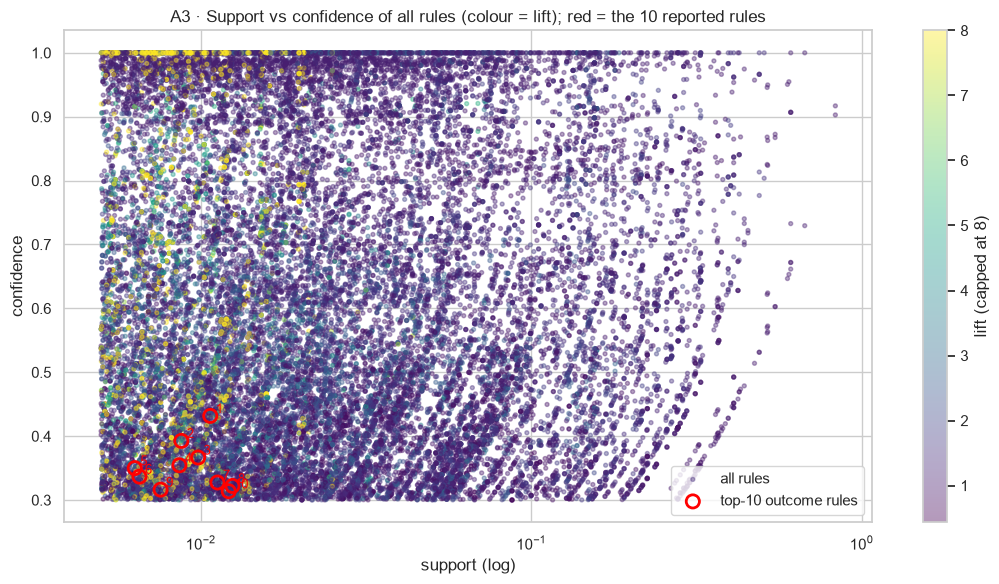

In [4]:
fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(rules.support, rules.confidence, c=rules.lift.clip(upper=8), s=8, cmap='viridis', alpha=0.4, label='all rules')
ax.scatter(top.head(10).support, top.head(10).confidence, s=90, facecolors='none', edgecolors='red', linewidths=2, label='top-10 outcome rules')
for i, r in top.head(10).reset_index().iterrows(): ax.annotate(str(i + 1), (r.support, r.confidence), fontsize=9, color='red', xytext=(4, 2), textcoords='offset points')
plt.colorbar(sc, label='lift (capped at 8)'); ax.set_xscale('log')
ax.set(title='A3 · Support vs confidence of all rules (colour = lift); red = the 10 reported rules', xlabel='support (log)', ylabel='confidence'); ax.legend()
save_fig('03_rule_map')

**Why this chart:** each dot is a rule. Good rules sit to the right (common enough) and high (reliable), with a bright colour (strong lift). The numbered red circles are the 10 rules interpreted below.

**🔎 Inference (A3): rule map**
- About 27,900 rules were generated, but **933 of the 946 "→ Exceedance/HighRisk" rules were definitional** (their antecedent already contained a ResultBand that *implies* the exceedance) and were removed. Only genuine, explanatory rules remain.
- The 10 reported rules (red) all have **support ≥ 0.6%** (thousands of results each), **confidence 31–43%** and **lift 4.0–5.5**. They are common enough to matter and make an exceedance 4–5 times more likely than the 7.8% overall rate.
- High-lift rules with tiny support (far left) are deliberately **not** reported as important, as the brief requires.

## 4 · The 10 reported rules with interpretation

In [5]:
ten = top.head(10)[['antecedents_s', 'consequents_s', 'support', 'confidence', 'lift']].reset_index(drop=True)
ten.index = [f'Rule {i + 1}' for i in range(len(ten))]
display(save_tab(ten.round(4), '04_ten_rules', index=True))

,antecedents_s,consequents_s,support,confidence,lift
Rule 1,Parameter=Temperature + Region=South + Season=Summer,Exceedance=Yes,0.0107,0.4317,5.5441
Rule 2,Equipment=Other + Season=Summer + WaterType=Surface Water,Exceedance=Yes,0.0087,0.3926,5.0419
Rule 3,Parameter=Dissolved oxygen + Season=Summer + WaterType=Surface Water,Exceedance=Yes,0.0098,0.3666,4.7074
Rule 4,Parameter=Dissolved oxygen + Region=South + Season=Summer,Exceedance=Yes,0.0086,0.3544,4.5515
Rule 5,Equipment=Other + Parameter=Temperature + Season=Summer,Exceedance=Yes,0.0063,0.3499,4.4941
Rule 6,Equipment=Bottle/grab sampler + Parameter=Dissolved oxygen + Season=Summer,Exceedance=Yes,0.0065,0.3366,4.3231
Rule 7,Region=South + Season=Summer + WaterType=Surface Water,Exceedance=Yes,0.0112,0.3275,4.2054
Rule 8,Equipment=Other + Region=South + Season=Summer,Exceedance=Yes,0.0125,0.3221,4.1363
Rule 9,Parameter=Dissolved oxygen + Region=Midwest + WaterType=Surface Water,Exceedance=Yes,0.0076,0.3163,4.0618
Rule 10,Group=Physical + Region=South + Season=Summer,Exceedance=Yes,0.0122,0.3137,4.0290


**🔎 Inference (A4): the 10 meaningful rules**
| # | If (antecedent) | Then | Support | Confidence | Lift |
|---|---|---|---|---|---|
| Rule 1 | Parameter=Temperature + Region=South + Season=Summer | Exceedance=Yes | 0.0107 | 0.432 | 5.54 |
| Rule 2 | Equipment=Other + Season=Summer + WaterType=Surface Water | Exceedance=Yes | 0.0087 | 0.393 | 5.04 |
| Rule 3 | Parameter=Dissolved oxygen + Season=Summer + WaterType=Surface Water | Exceedance=Yes | 0.0098 | 0.367 | 4.71 |
| Rule 4 | Parameter=Dissolved oxygen + Region=South + Season=Summer | Exceedance=Yes | 0.0086 | 0.354 | 4.55 |
| Rule 5 | Equipment=Other + Parameter=Temperature + Season=Summer | Exceedance=Yes | 0.0063 | 0.350 | 4.49 |
| Rule 6 | Equipment=Bottle/grab sampler + Parameter=Dissolved oxygen + Season=Summer | Exceedance=Yes | 0.0065 | 0.337 | 4.32 |
| Rule 7 | Region=South + Season=Summer + WaterType=Surface Water | Exceedance=Yes | 0.0112 | 0.328 | 4.21 |
| Rule 8 | Equipment=Other + Region=South + Season=Summer | Exceedance=Yes | 0.0125 | 0.322 | 4.14 |
| Rule 9 | Parameter=Dissolved oxygen + Region=Midwest + WaterType=Surface Water | Exceedance=Yes | 0.0076 | 0.316 | 4.06 |
| Rule 10 | Group=Physical + Region=South + Season=Summer | Exceedance=Yes | 0.0122 | 0.314 | 4.03 |

**What they say, in plain words:**
- **Summer is the common thread.** 9 of the 10 rules include *Season = Summer*: most exceedance combinations happen in warm months.
- **The South in summer** (rules 1, 4, 7, 8, 10) is the riskiest combination: southern summer **temperature** readings exceed 43% of the time (lift 5.5), and southern summer **DO** readings 35% of the time.
- **Low oxygen in summer surface water** (rules 3, 6, 9) is a nationwide pattern, including the Midwest (rule 9).
- **Equipment = Other / grab sampler** items (rules 2, 5, 6, 8) reflect *which monitoring programmes* sample problem waters in summer. This is a monitoring pattern, not a cause.

**Possible use:**
- Schedule extra summer DO/temperature monitoring and alerts for southern surface waters.
- Use these combinations as alert rules in the real-time dashboard.
- These are co-occurrences, not proof of cause.